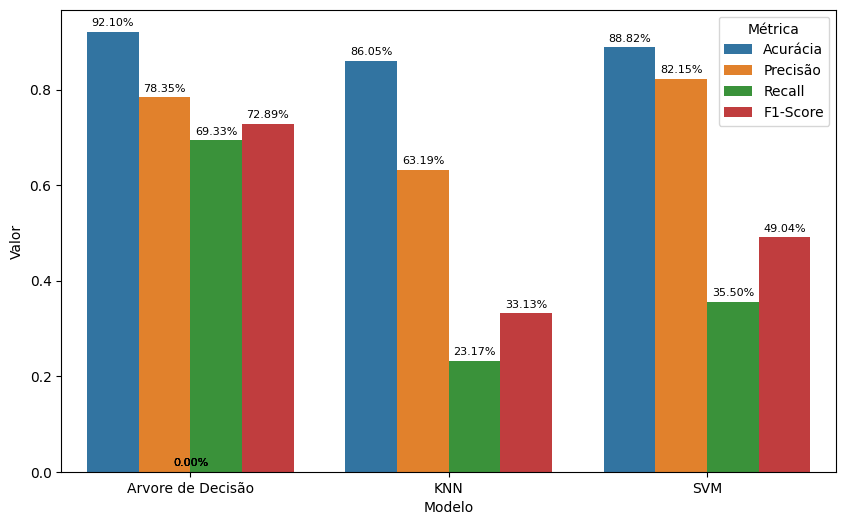

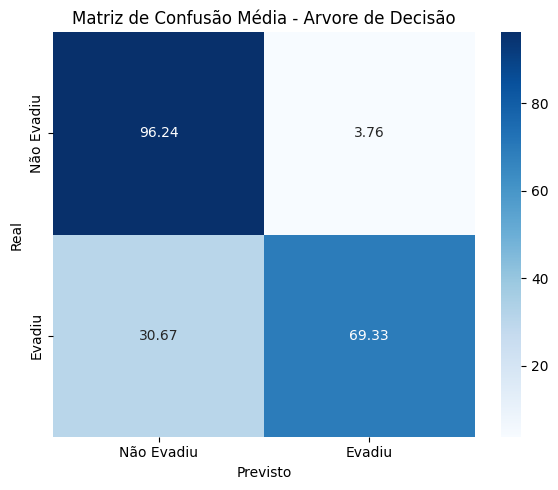

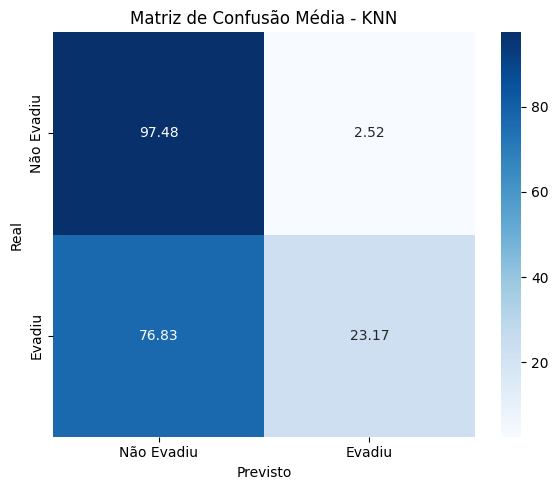

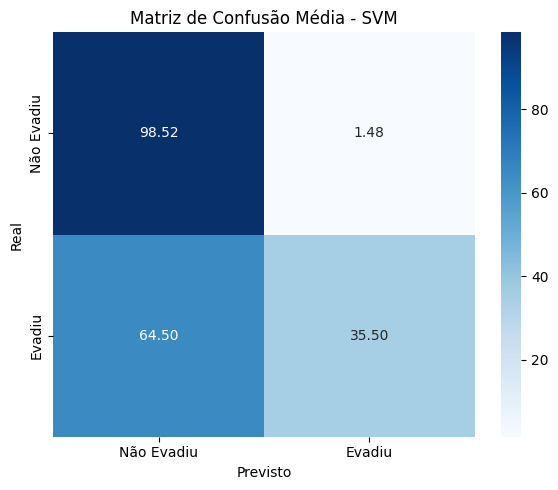

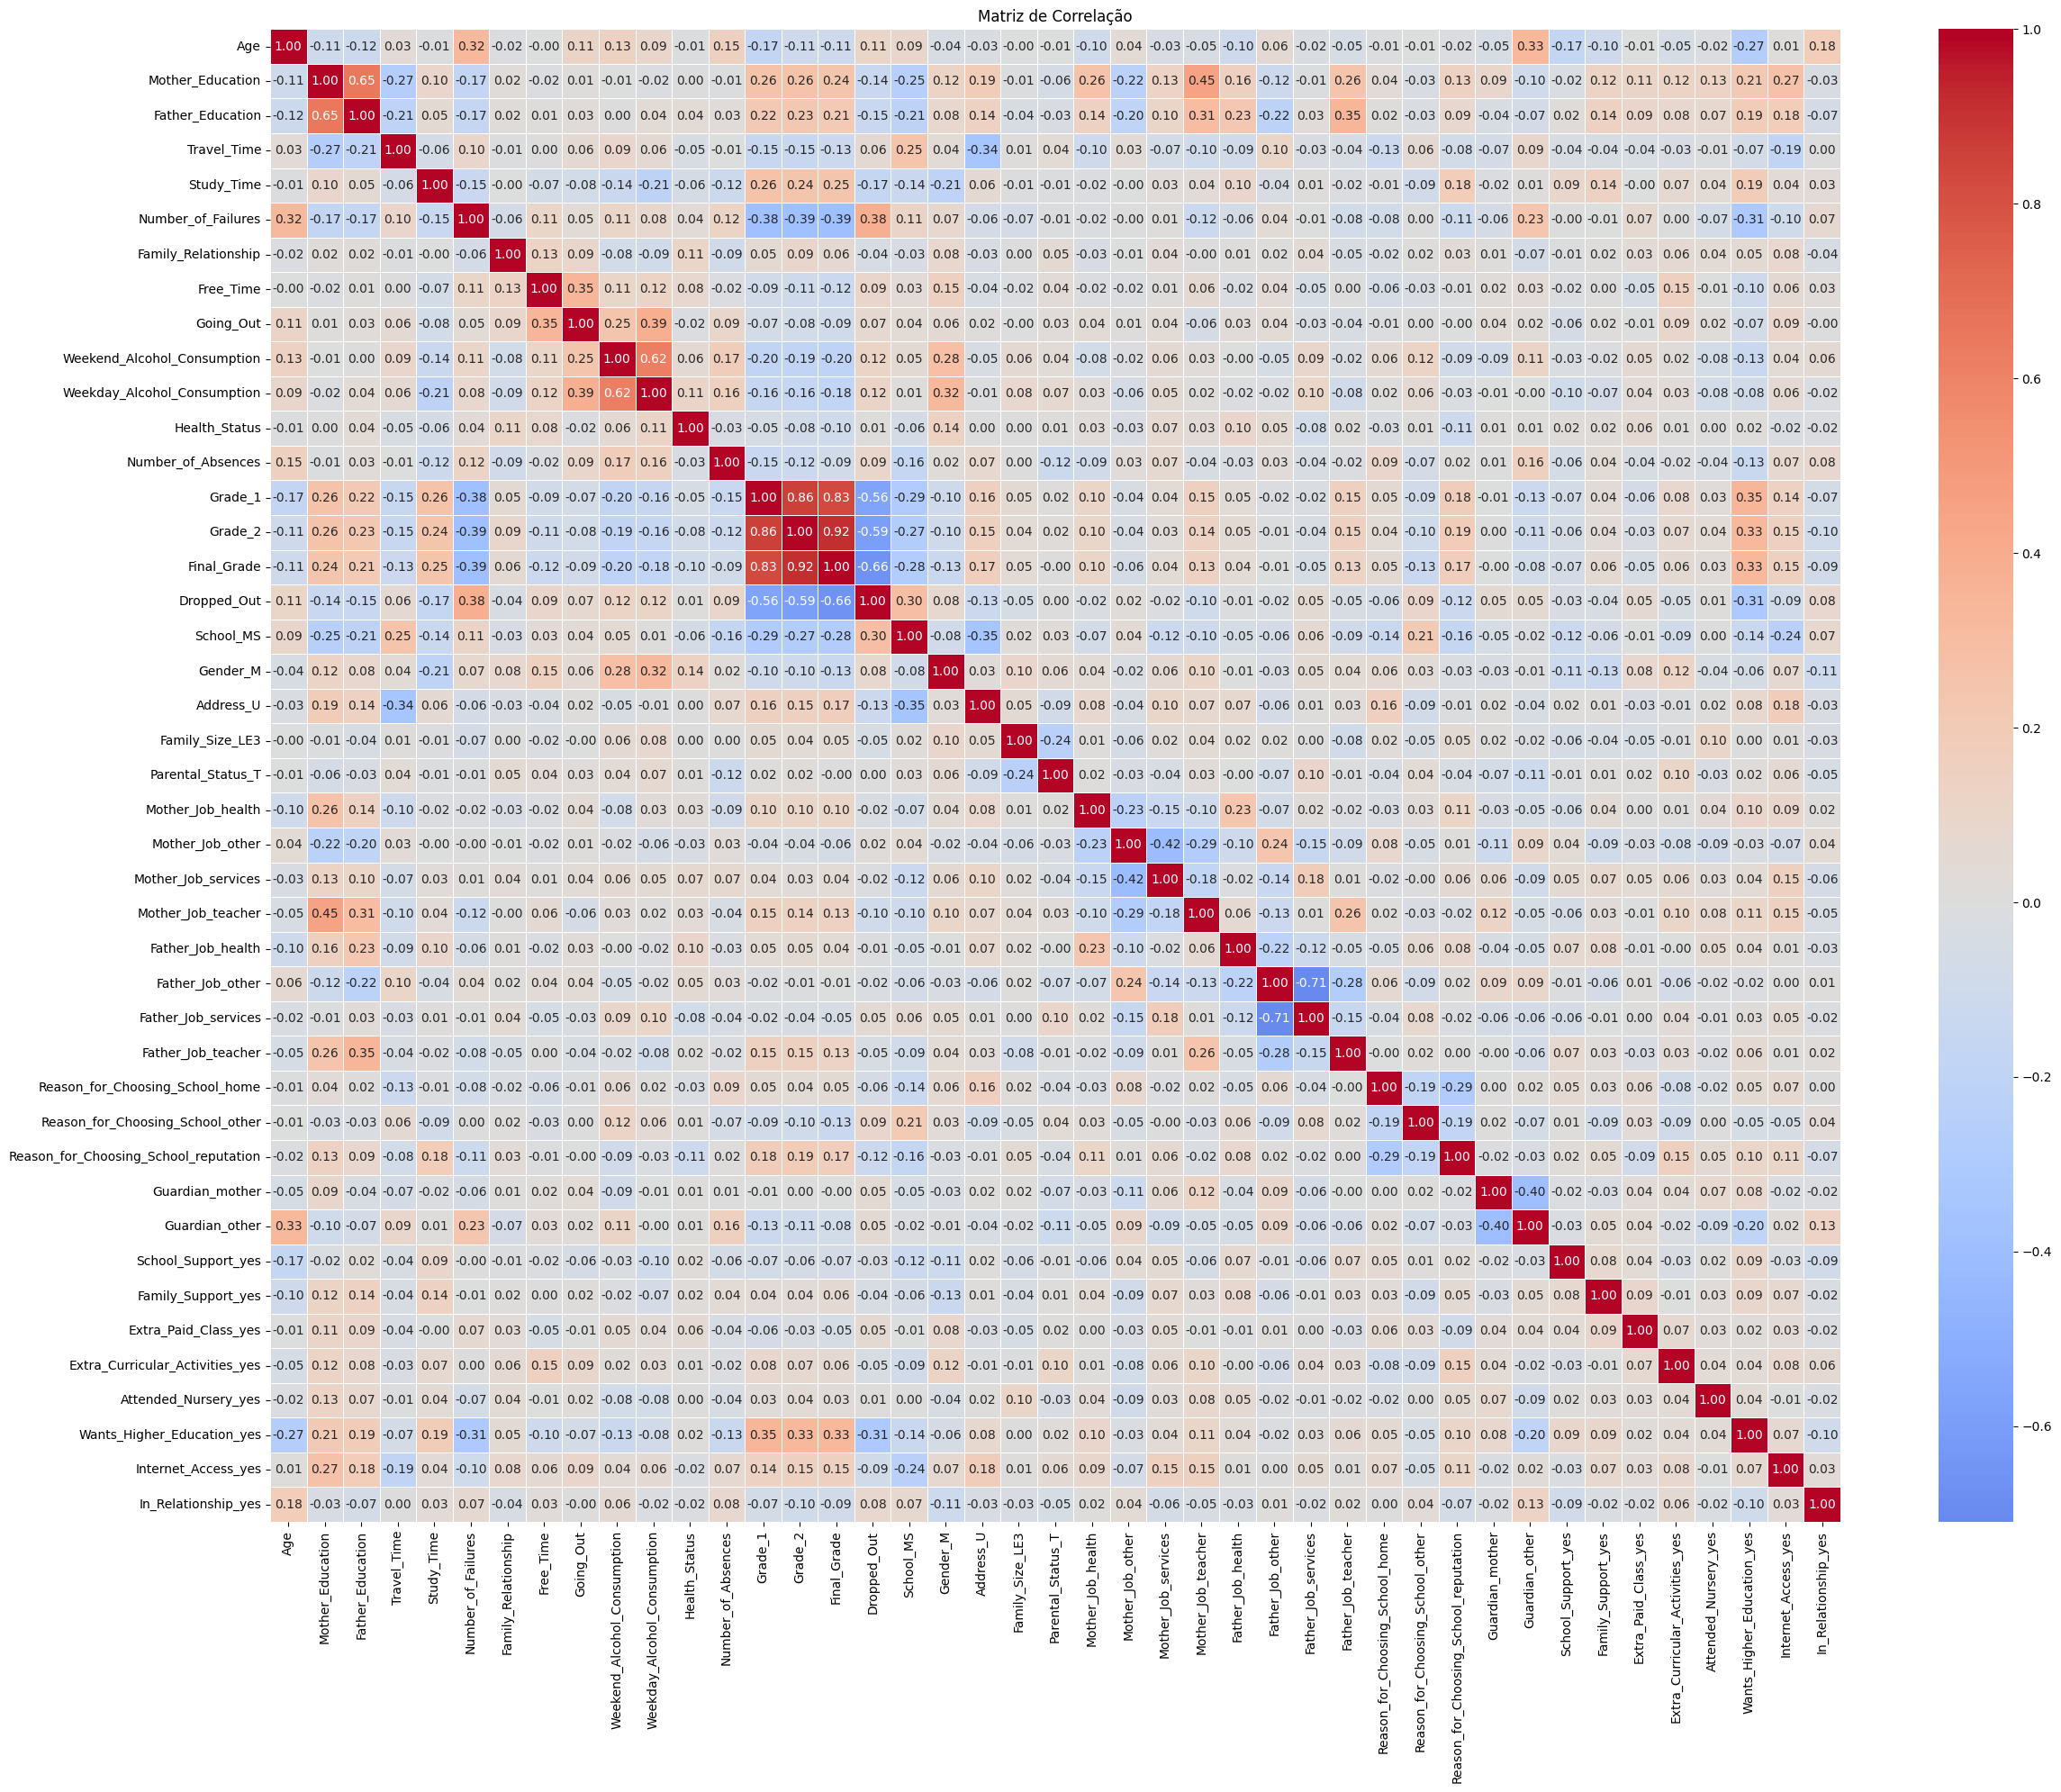

RELATÓRIO DE CLASSIFICAÇÃO

Modelo: Arvore de Decisão

              precision    recall  f1-score   support

           0       0.97      0.96      0.96       165
           1       0.78      0.83      0.81        30

    accuracy                           0.94       195
   macro avg       0.88      0.90      0.88       195
weighted avg       0.94      0.94      0.94       195


Modelo: KNN

              precision    recall  f1-score   support

           0       0.88      0.97      0.92       165
           1       0.64      0.30      0.41        30

    accuracy                           0.87       195
   macro avg       0.76      0.63      0.67       195
weighted avg       0.85      0.87      0.85       195


Modelo: SVM

              precision    recall  f1-score   support

           0       0.88      0.98      0.93       165
           1       0.67      0.27      0.38        30

    accuracy                           0.87       195
   macro avg       0.77      0.62      0.65  

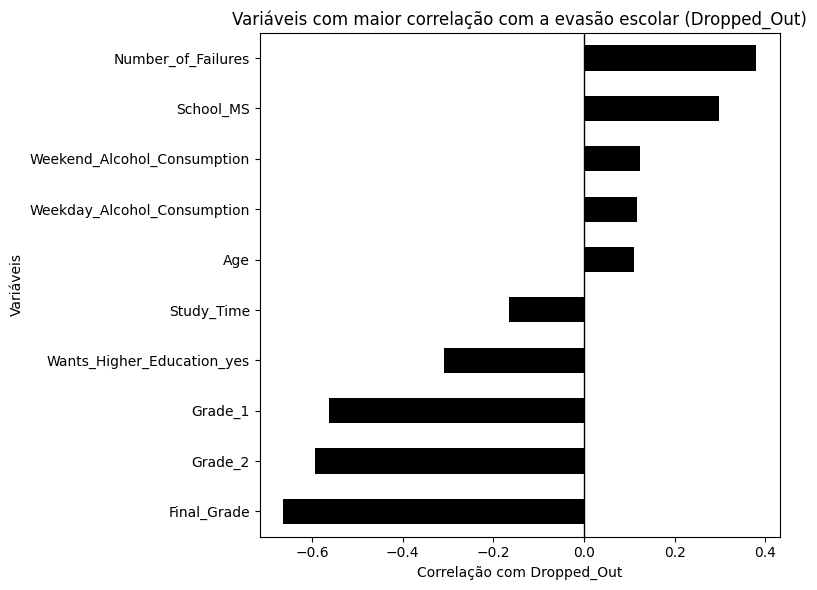

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

base = pd.read_csv("student dropout.csv")

x = base.drop(columns=['Dropped_Out', 'Final_Grade'])
y = base['Dropped_Out'].astype(int)

# Transformação de variáveis categóricas
x = pd.get_dummies(x, drop_first=True)

# TREINAMENTO E AVALIAÇÃO DOS MODELOS

resultados = []

# Para acumular as matrizes de confusão
matrizes_confusao = {
    'Arvore de Decisão': [],
    'KNN': [],
    'SVM': []
}

# MODELOS

# Divisão em treino e teste
for i in range(20):
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.3, random_state=i, stratify=y
    )

    # Normalização
    scaler = StandardScaler()

    x_train_scaled = scaler.fit_transform(x_train)
    x_test_scaled = scaler.transform(x_test)

    modelos = {
        'Arvore de Decisão': DecisionTreeClassifier(max_depth=5, min_samples_split=10, min_samples_leaf=5,random_state=42),
        'KNN': KNeighborsClassifier(n_neighbors=5),
        'SVM': SVC(kernel='rbf', random_state=42)
    }

    for nome_modelo, modelo in modelos.items():

        # Treinamento dos modelos
        modelo.fit(x_train_scaled, y_train)

        # Predição dos modelos
        y_pred = modelo.predict(x_test_scaled)

        # Acumula as matrizes de confusão
        cm = confusion_matrix(y_test, y_pred)
        matrizes_confusao[nome_modelo].append(cm)

        # Métricas
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred)
        rec = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)

        resultados.append({
            'Modelo': nome_modelo,
            'Acurácia': acc,
            'Precisão': prec,
            'Recall': rec,
            'F1-Score': f1,
        })

df_resultados = pd.DataFrame(resultados)

medias = df_resultados.groupby('Modelo').mean()
desvios = df_resultados.groupby('Modelo').std()

# GRÁFICO DE BARRAS

# Resetando índice
medias_reset = medias.reset_index()

# Transformando formato do DataFrame
medias_melt = medias_reset.melt(
    id_vars='Modelo',
    var_name='Métrica',
    value_name='Valor'
)

# Criação do gráfico
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=medias_melt,
    x='Modelo',
    y='Valor',
    hue='Métrica'
)

# Adiciona os valores nas barras
for barra in ax.patches:
    altura = barra.get_height()

    ax.annotate(
        f'{altura*100:.2f}%',
        (barra.get_x() + barra.get_width() / 2, altura),
        ha='center',
        va='bottom',
        fontsize=8,
        xytext=(0, 3),
        textcoords='offset points'
    )

# MATRIZES DE CONFUSÃO

for nome, lista_cm in matrizes_confusao.items():

    # Média das 20 matrizes
    cm_media = np.mean(lista_cm, axis=0)

    # Percentuais por linha
    cm_percent = (
        cm_media /
        cm_media.sum(axis=1, keepdims=True)
    ) * 100

    plt.figure(figsize=(6, 5))

    sns.heatmap(
    cm_percent,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    xticklabels=['Não Evadiu', 'Evadiu'],
    yticklabels=['Não Evadiu', 'Evadiu']
)

    plt.title(f'Matriz de Confusão Média - {nome}')
    plt.xlabel('Previsto')
    plt.ylabel('Real')
    plt.tight_layout()
    plt.show()

# MATRIZ DE CORRELAÇÃO

dados_corr = pd.get_dummies(base, drop_first=True)
matriz_correlacao = dados_corr.corr()
plt.figure(figsize=(25, 20))

sns.heatmap(
    matriz_correlacao,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title("Matriz de Correlação")
plt.tight_layout()
plt.show()

print("RELATÓRIO DE CLASSIFICAÇÃO") # só tá mostrando a última iteração

for nome_modelo, modelo in modelos.items():
    modelo.fit(x_train_scaled, y_train)
    y_pred = modelo.predict(x_test_scaled)
    print(f"\nModelo: {nome_modelo}\n")
    print(classification_report(y_test, y_pred))

print('\nMÉDIAS DAS MÉTRICAS:\n')

media_acuracia = df_resultados['Acurácia'].mean()
media_precisao = df_resultados['Precisão'].mean()
media_recall = df_resultados['Recall'].mean()
media_f1 = df_resultados['F1-Score'].mean()

print(f'Média da Acurácia: {media_acuracia:.4f}')
print(f'Média da Precisão: {media_precisao:.4f}')
print(f'Média do Recall: {media_recall:.4f}')
print(f'Média do F1-Score: {media_f1:.4f}')

tabela_medias = (
    df_resultados
    .groupby('Modelo')
    [['Acurácia',
      'Precisão',
      'Recall',
      'F1-Score']]
    .mean()
    .mul(100)
    .round(2)
    .astype(str)
    + '%'
)

print("\nMÉDIAS (%)\n")
print(tabela_medias)

tabela_desvios = (
    df_resultados
    .groupby('Modelo')
    [['Acurácia',
      'Precisão',
      'Recall',
      'F1-Score']]
    .std()
    .mul(100)
    .round(2)
    .astype(str)
    + '%'
)

print("\nDESVIOS PADRÃO (%)\n")
print(tabela_desvios)

print(y.value_counts())
print(y.value_counts(normalize=True) * 100)

# MATRIZ DE CORRELAÇÃO - RELAÇÃO DAS VARIÁVEIS COM DROPPED_OUT

# Transformação das variáveis categóricas
dados_corr = pd.get_dummies(base, drop_first=True)

# Calcula a correlação de todas as variáveis com a variável de evasão
correlacao_evasao = dados_corr.corr()['Dropped_Out']

# Remove a própria variável Dropped_Out
correlacao_evasao = correlacao_evasao.drop('Dropped_Out')

# Ordena as correlações do menor para o maior valor
correlacao_evasao = correlacao_evasao.sort_values()

# Seleciona as 10 variáveis com maior associação
variaveis_relevantes = pd.concat([
    correlacao_evasao.head(5),
    correlacao_evasao.tail(5)
])


# CRIAÇÃO DO GRÁFICO MONOCROMÁTICO

plt.figure(figsize=(8, 6))

ax = variaveis_relevantes.plot(
    kind='barh',
    color='black'
)

plt.title(
    "Variáveis com maior correlação com a evasão escolar (Dropped_Out)"
)

plt.xlabel(
    "Correlação com Dropped_Out"
)

plt.ylabel(
    "Variáveis"
)

# Linha vertical no zero para separar correlações positivas e negativas
plt.axvline(
    0,
    color='black',
    linewidth=1
)

# Fundo branco
plt.gca().set_facecolor('white')

# Ajuste da visualização
plt.tight_layout()

# Salvar imagem em alta resolução
plt.savefig(
    "correlacao_dropped_out.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()